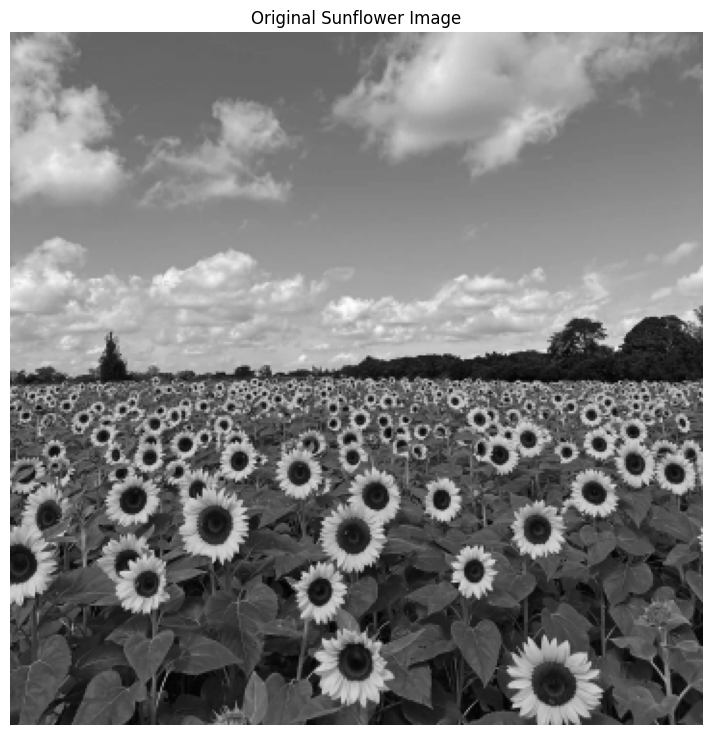

Image dimensions: (360, 360)


In [32]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# Read the sunflower image at a reduced resolution
image = cv.imread(
    '/the_berry_farms_sunflower_field.jpeg',
    cv.IMREAD_REDUCED_COLOR_4
)

assert image is not None, "Could not load the sunflower image."

# Convert the image to grayscale and normalize pixel values
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# Display the input image
plt.figure(figsize=(9, 9))
plt.imshow(gray_image, cmap='gray')
plt.title('Original Sunflower Image')
plt.axis('off')
plt.show()

print("Image dimensions:", gray_image.shape)

In [33]:
# Define the scales to examine
scales = np.linspace(1, 8, 10)

# Set the threshold for accepting blob responses
response_threshold = 0.6

# Store the detected blobs
detected_blobs = []

height, width = gray_image.shape

for sigma in scales:

    print(f"Processing sigma = {sigma:.2f}")

    # Construct the LoG kernel
    half_size = round(3 * sigma)
    xx, yy = np.meshgrid(
        np.arange(-half_size, half_size + 1),
        np.arange(-half_size, half_size + 1)
    )

    distance_squared = xx**2 + yy**2

    log_kernel = (
        (distance_squared / (2 * sigma**2) - 1)
        * np.exp(-distance_squared / (2 * sigma**2))
        / (np.pi * sigma**4)
    )

    # Normalize the filter response with sigma squared
    log_kernel = sigma**2 * log_kernel

    # Apply the filter and calculate the squared response
    response = cv.filter2D(
        gray_image, cv.CV_32F, log_kernel
    )
    response = response**2

    # Find local maxima in a 3 x 3 neighbourhood
    neighbourhood_max = maximum_filter(response, size=3)

    # Keep local maxima whose responses exceed the threshold
    threshold_value = response_threshold * response.max()

    maxima_mask = (
        (response == neighbourhood_max)
        & (response >= threshold_value)
    )

    # Get the coordinates of the detected maxima
    rows, cols = np.where(maxima_mask)

    for row, col in zip(rows, cols):
        detected_blobs.append(
            (col, row, sigma, response[row, col])
        )

print("\nTotal candidate detections:", len(detected_blobs))

Processing sigma = 1.00
Processing sigma = 1.78
Processing sigma = 2.56
Processing sigma = 3.33
Processing sigma = 4.11
Processing sigma = 4.89
Processing sigma = 5.67
Processing sigma = 6.44
Processing sigma = 7.22
Processing sigma = 8.00

Total candidate detections: 131


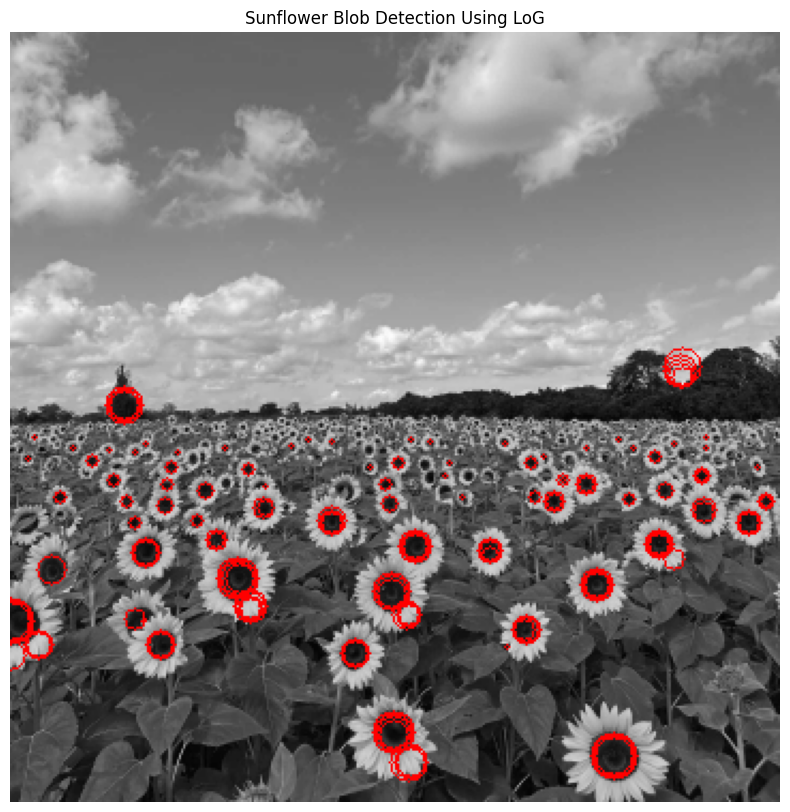

Largest detected blob:
Centre: (0, 275)
Sigma: 8.00
Radius: 11 pixels
Diameter: 22 pixels
Response strength: 0.10328


In [36]:
# Sort detections by radius, from largest to smallest
detected_blobs.sort(
    key=lambda blob: 2 * blob[2],
    reverse=True
)

# Prepare the image for drawing circles
result_image = cv.cvtColor(
    (gray_image * 255).astype(np.uint8),
    cv.COLOR_GRAY2BGR
)

# Draw all detected circles
for x, y, sigma, strength in detected_blobs:
    radius = int(round(np.sqrt(2) * sigma))

    cv.circle(
        result_image,
        (int(x), int(y)),
        radius,
        (0, 0, 255),
        1
    )

# Display the detection result
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(result_image, cv.COLOR_BGR2RGB))
plt.title('Sunflower Blob Detection Using LoG')
plt.axis('off')
plt.show()

# Report the largest detection based on radius
if detected_blobs:
    largest_blob = max(detected_blobs, key=lambda blob: 2 * blob[2])

    x, y, sigma, strength = largest_blob
    radius = int(round(np.sqrt(2) * sigma))

    print("Largest detected blob:")
    print(f"Centre: ({x}, {y})")
    print(f"Sigma: {sigma:.2f}")
    print(f"Radius: {radius} pixels")
    print(f"Diameter: {2 * radius} pixels")
    print(f"Response strength: {strength:.5f}")
else:
    print("No blobs were detected.")

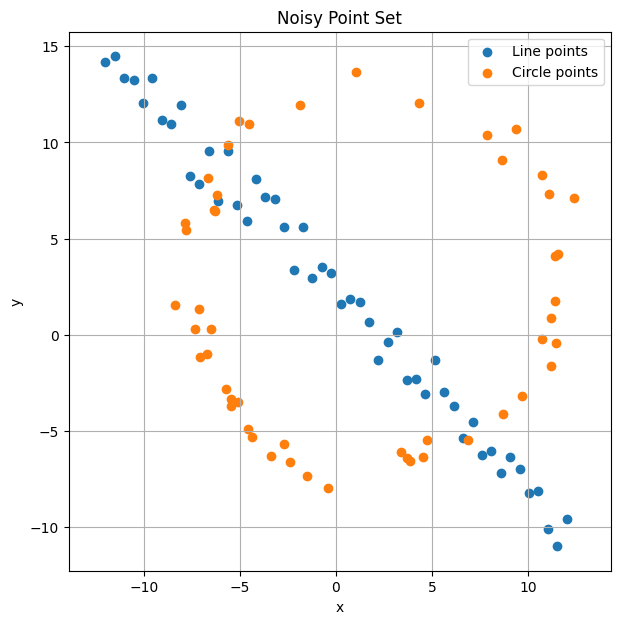

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)

# Generate points belonging to a circle and a line
N = 100
n_points = N // 2

# Circle parameters
radius_true = 10
center_x, center_y = 2, 3

angles = np.random.uniform(0, 2 * np.pi, n_points)
noise_circle = (radius_true / 16) * np.random.randn(n_points)

circle_x = center_x + (radius_true + noise_circle) * np.cos(angles)
circle_y = center_y + (radius_true + noise_circle) * np.sin(angles)

circle_points = np.column_stack((circle_x, circle_y))

# Line parameters
slope_true, intercept_true = -1, 2

line_x = np.linspace(-12, 12, n_points)
line_y = slope_true * line_x + intercept_true + np.random.randn(n_points)

line_points = np.column_stack((line_x, line_y))

# Combine both sets of points
points = np.vstack((circle_points, line_points))

# Display the generated data
plt.figure(figsize=(7, 7))
plt.scatter(line_points[:, 0], line_points[:, 1], label="Line points")
plt.scatter(circle_points[:, 0], circle_points[:, 1], label="Circle points")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy Point Set")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# Calculate perpendicular distances from points to a line
def distance_to_line(model, data):
    a, b, d = model
    return np.abs(a * data[:, 0] + b * data[:, 1] + d)


# Estimate a line using RANSAC
def fit_line_ransac(data, iterations=1000, tolerance=0.6, min_consensus=35):
    best_model = None
    best_inliers = np.array([], dtype=int)

    for _ in range(iterations):
        sample = np.random.choice(len(data), 2, replace=False)
        p1, p2 = data[sample]

        a = p2[1] - p1[1]
        b = p1[0] - p2[0]
        d = -(a * p1[0] + b * p1[1])

        norm = np.sqrt(a**2 + b**2)
        if norm == 0:
            continue

        model = np.array([a, b, d]) / norm

        distances = distance_to_line(model, data)
        inlier_indices = np.where(distances < tolerance)[0]

        if (len(inlier_indices) > len(best_inliers)
                and len(inlier_indices) >= min_consensus):
            best_model = model
            best_inliers = inlier_indices

    return best_model, best_inliers


# Calculate radial distances from points to a circle
def distance_to_circle(model, data):
    cx, cy, radius = model
    distances = np.sqrt(
        (data[:, 0] - cx)**2 + (data[:, 1] - cy)**2
    )
    return np.abs(distances - radius)


# Estimate a circle using RANSAC
def fit_circle_ransac(data, iterations=1000, tolerance=1.5, min_consensus=45):
    best_model = None
    best_inliers = np.array([], dtype=int)

    for _ in range(iterations):
        sample_indices = np.random.choice(len(data), 3, replace=False)
        p1, p2, p3 = data[sample_indices]

        matrix = np.array([
            [p1[0], p1[1], 1],
            [p2[0], p2[1], 1],
            [p3[0], p3[1], 1]
        ])

        values = -np.array([
            p1[0]**2 + p1[1]**2,
            p2[0]**2 + p2[1]**2,
            p3[0]**2 + p3[1]**2
        ])

        try:
            solution = np.linalg.solve(matrix, values)
        except np.linalg.LinAlgError:
            continue

        cx = -solution[0] / 2
        cy = -solution[1] / 2
        radius_squared = cx**2 + cy**2 - solution[2]

        if radius_squared <= 0:
            continue

        radius = np.sqrt(radius_squared)
        model = np.array([cx, cy, radius])

        distances = distance_to_circle(model, data)
        inlier_indices = np.where(distances < tolerance)[0]

        if (len(inlier_indices) > len(best_inliers)
                and len(inlier_indices) >= min_consensus):
            best_model = model
            best_inliers = inlier_indices

    return best_model, best_inliers


# Fit the line first
line_model, line_inlier_indices = fit_line_ransac(points)

if line_model is None:
    raise RuntimeError("RANSAC could not find a suitable line.")

# Remove line inliers before fitting the circle
remaining_indices = np.setdiff1d(
    np.arange(len(points)), line_inlier_indices
)
remaining_points = points[remaining_indices]

circle_model, circle_inlier_indices = fit_circle_ransac(remaining_points)

if circle_model is None:
    raise RuntimeError("RANSAC could not find a suitable circle.")

# Convert circle inlier indices to indices in the original point set
circle_inlier_indices = remaining_indices[circle_inlier_indices]

print("Line model [a, b, d]:", line_model)
print("Number of line inliers:", len(line_inlier_indices))

print("\nCircle model [cx, cy, radius]:", circle_model)
print("Number of circle inliers:", len(circle_inlier_indices))

Line model [a, b, d]: [-0.7184192  -0.69561041  1.47534491]
Number of line inliers: 36

Circle model [cx, cy, radius]: [ 2.07320166  3.03114827 10.11033487]
Number of circle inliers: 52


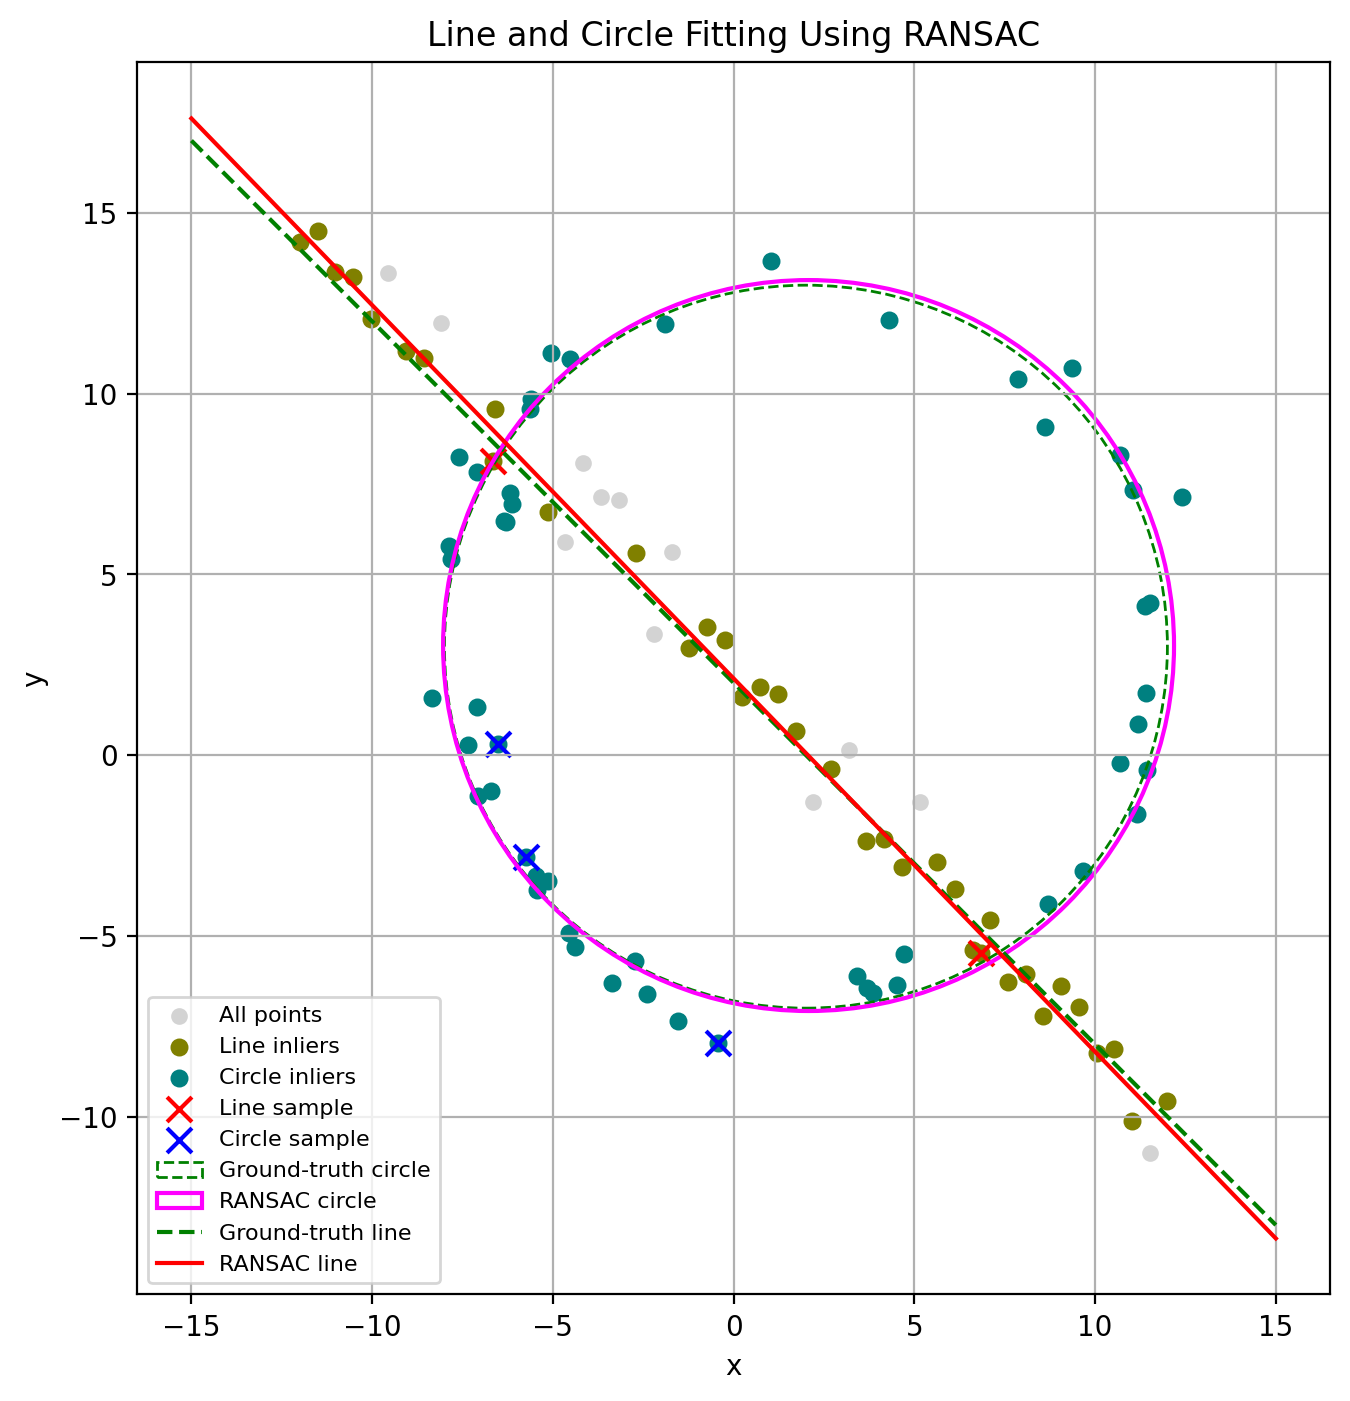

In [39]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=200)

# Plot all points
ax.scatter(points[:, 0], points[:, 1], s=25,
           color="lightgray", label="All points")

# Highlight the line and circle inliers
ax.scatter(points[line_inlier_indices, 0],
           points[line_inlier_indices, 1],
           s=30, color="olive", label="Line inliers")

ax.scatter(points[circle_inlier_indices, 0],
           points[circle_inlier_indices, 1],
           s=30, color="teal", label="Circle inliers")

# Highlight the samples used for the final RANSAC models
# These are representative inlier samples, not necessarily
# the original random samples that produced the best models.
ax.scatter(points[line_inlier_indices[:2], 0],
           points[line_inlier_indices[:2], 1],
           color="red", marker="x", s=80, label="Line sample")

ax.scatter(points[circle_inlier_indices[:3], 0],
           points[circle_inlier_indices[:3], 1],
           color="blue", marker="x", s=80, label="Circle sample")

# Plot the ground-truth circle
true_circle = plt.Circle(
    (center_x, center_y), radius_true,
    fill=False, color="green", linestyle="--",
    label="Ground-truth circle"
)
ax.add_patch(true_circle)

# Plot the estimated circle
cx, cy, estimated_radius = circle_model
fitted_circle = plt.Circle(
    (cx, cy), estimated_radius,
    fill=False, color="magenta", linewidth=1.5,
    label="RANSAC circle"
)
ax.add_patch(fitted_circle)

# Plot the ground-truth line
x_range = np.array([-15, 15])
ax.plot(
    x_range, slope_true * x_range + intercept_true,
    color="green", linestyle="--", label="Ground-truth line"
)

# Plot the estimated line
a, b, d = line_model

if abs(b) > 1e-8:
    ax.plot(
        x_range, -(a * x_range + d) / b,
        color="red", label="RANSAC line"
    )
else:
    x_line = -d / a
    ax.axvline(x_line, color="red", label="RANSAC line")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Line and Circle Fitting Using RANSAC")
ax.set_aspect("equal", adjustable="box")
ax.legend(fontsize=8)
ax.grid(True)
plt.show()

Background image size: (480, 680, 3)
Overlay image size: (3334, 5000, 3)


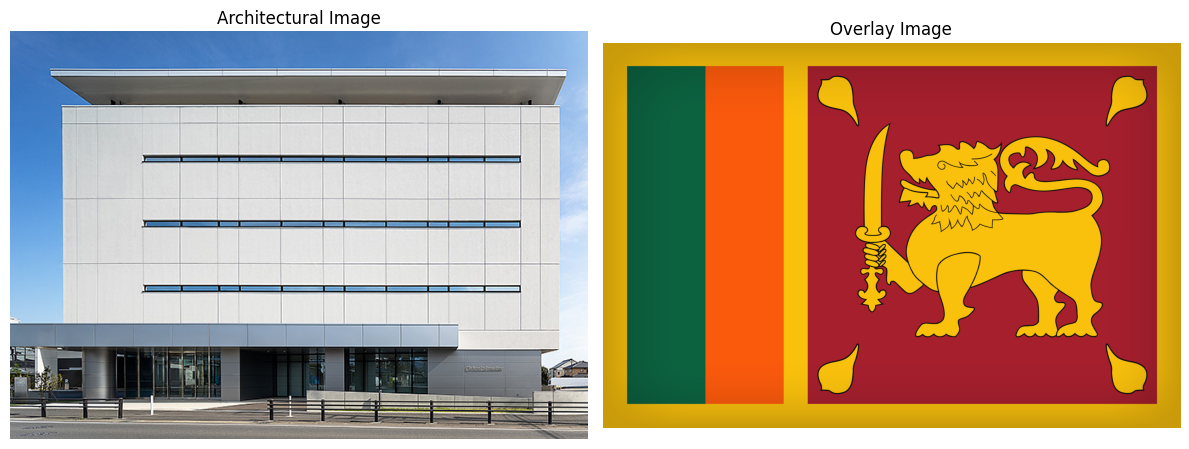

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the architectural image and the image to be projected
building_path = '/building1.jpg'
overlay_path = '/flag1.png'

building = cv2.imread(building_path)
overlay = cv2.imread(overlay_path)

if building is None or overlay is None:
    raise FileNotFoundError("Check the image paths and filenames.")

print("Background image size:", building.shape)
print("Overlay image size:", overlay.shape)

# Display both input images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(building, cv2.COLOR_BGR2RGB))
plt.title("Architectural Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [1]:
# Make a copy for displaying the selected points
display_image = building.copy()
selected_points = []

def choose_corners(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(selected_points) < 4:
        selected_points.append([x, y])

        # Mark the selected corner
        cv2.circle(display_image, (x, y), 6, (0, 255, 0), -1)
        cv2.putText(
            display_image,
            str(len(selected_points)),
            (x + 8, y - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        cv2.imshow("Select four corners", display_image)
        print(f"Selected point {len(selected_points)}: ({x}, {y})")

# Open the image window
cv2.namedWindow("Select four corners")
cv2.imshow("Select four corners", display_image)
cv2.setMouseCallback("Select four corners", choose_corners)

print("Click the four surface corners in clockwise order.")
print("Press any key after selecting all four points.")

while len(selected_points) < 4:
    if cv2.waitKey(20) & 0xFF == 27:
        break

cv2.waitKey(0)
cv2.destroyAllWindows()

if len(selected_points) != 4:
    raise ValueError("Exactly four points must be selected.")

destination_points = np.array(selected_points, dtype=np.float32)

# Get the four corners of the overlay image
overlay_height, overlay_width = overlay.shape[:2]

source_points = np.array([
    [0, 0],
    [overlay_width - 1, 0],
    [overlay_width - 1, overlay_height - 1],
    [0, overlay_height - 1]
], dtype=np.float32)

# Compute the homography mapping overlay coordinates to the surface
H, status = cv2.findHomography(source_points, destination_points)

if H is None:
    raise RuntimeError("Homography estimation failed.")

print("Homography matrix:")
print(H)

NameError: name 'building' is not defined